In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
pd.set_option('display.float_format', '{:,.2f}'.format)

In [3]:
df=pd.read_csv('train.csv')

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_20572\3155070436.py:1: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv('train.csv')


In [4]:
df_store_info = pd.read_csv('store.csv')

In [5]:
df = df.merge(df_store_info, on='Store', how='left')

In [6]:
df['StateHoliday'].unique()

array(['0', 'a', 'b', 'c', 0], dtype=object)

In [7]:
df.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,"1,270.00",9.00,"2,008.00",0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.00,11.00,"2,007.00",1,13.00,"2,010.00","Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,"14,130.00",12.00,"2,006.00",1,14.00,"2,011.00","Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.00,9.00,"2,009.00",0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,"29,910.00",4.00,"2,015.00",0,NaN,NaN,NaN


In [8]:
df.shape

(1017209, 18)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 18 columns):
 #   Column                     Non-Null Count    Dtype  
---  ------                     --------------    -----  
 0   Store                      1017209 non-null  int64  
 1   DayOfWeek                  1017209 non-null  int64  
 2   Date                       1017209 non-null  object 
 3   Sales                      1017209 non-null  int64  
 4   Customers                  1017209 non-null  int64  
 5   Open                       1017209 non-null  int64  
 6   Promo                      1017209 non-null  int64  
 7   StateHoliday               1017209 non-null  object 
 8   SchoolHoliday              1017209 non-null  int64  
 9   StoreType                  1017209 non-null  object 
 10  Assortment                 1017209 non-null  object 
 11  CompetitionDistance        1014567 non-null  float64
 12  CompetitionOpenSinceMonth  693861 non-null   float64
 13  CompetitionO

indicates a state holiday. Normally all stores, with few exceptions, are closed on state holidays. Note that all schools are closed on public holidays and weekends. a = public holiday, b = Easter holiday, c = Christmas, 0 = None

In [10]:
df.duplicated().sum()

0

In [11]:
df.isna().sum()/df.shape[0]*100

Store                        0.00
DayOfWeek                    0.00
Date                         0.00
Sales                        0.00
Customers                    0.00
Open                         0.00
Promo                        0.00
StateHoliday                 0.00
SchoolHoliday                0.00
StoreType                    0.00
Assortment                   0.00
CompetitionDistance          0.26
CompetitionOpenSinceMonth   31.79
CompetitionOpenSinceYear    31.79
Promo2                       0.00
Promo2SinceWeek             49.94
Promo2SinceYear             49.94
PromoInterval               49.94
dtype: float64

In [12]:
df.drop(columns=['Promo2SinceWeek','Promo2SinceYear','PromoInterval','CompetitionOpenSinceMonth','CompetitionOpenSinceYear'],inplace=True)

In [13]:
df['CompetitionDistance']=df['CompetitionDistance'].fillna(0)

In [14]:
df['Store'].nunique()

1115

In [15]:
df.describe()

,Store,DayOfWeek,Sales,Customers,Open,Promo,SchoolHoliday,CompetitionDistance,Promo2
count,"1,017,209.00","1,017,209.00","1,017,209.00","1,017,209.00","1,017,209.00","1,017,209.00","1,017,209.00","1,017,209.00","1,017,209.00"
mean,558.43,4.00,"5,773.82",633.15,0.83,0.38,0.18,"5,415.98",0.50
std,321.91,2.00,"3,849.93",464.41,0.38,0.49,0.38,"7,710.25",0.50
min,1.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,280.00,2.00,"3,727.00",405.00,1.00,0.00,0.00,700.00,0.00
50%,558.00,4.00,"5,744.00",609.00,1.00,0.00,0.00,"2,320.00",1.00
75%,838.00,6.00,"7,856.00",837.00,1.00,1.00,0.00,"6,880.00",1.00
max,"1,115.00",7.00,"41,551.00","7,388.00",1.00,1.00,1.00,"75,860.00",1.00


In [16]:
df.select_dtypes(include=['number']).corr()

,Store,DayOfWeek,Sales,Customers,Open,Promo,SchoolHoliday,CompetitionDistance,Promo2
Store,1.00,-0.00,0.01,0.02,-0.00,0.00,0.00,-0.03,0.01
DayOfWeek,-0.00,1.00,-0.46,-0.39,-0.53,-0.39,-0.21,-0.00,0.00
Sales,0.01,-0.46,1.00,0.89,0.68,0.45,0.09,-0.02,-0.09
Customers,0.02,-0.39,0.89,1.00,0.62,0.32,0.07,-0.10,-0.15
Open,-0.00,-0.53,0.68,0.62,1.00,0.30,0.09,0.01,-0.01
Promo,0.00,-0.39,0.45,0.32,0.30,1.00,0.07,0.00,-0.00
SchoolHoliday,0.00,-0.21,0.09,0.07,0.09,0.07,1.00,-0.00,-0.01
CompetitionDistance,-0.03,-0.00,-0.02,-0.10,0.01,0.00,-0.00,1.00,-0.14
Promo2,0.01,0.00,-0.09,-0.15,-0.01,-0.00,-0.01,-0.14,1.00


In [17]:
df['Date'].min()


'2013-01-01'

In [18]:
df['Date'].max()

'2015-07-31'

## Phase 2: Business Understanding

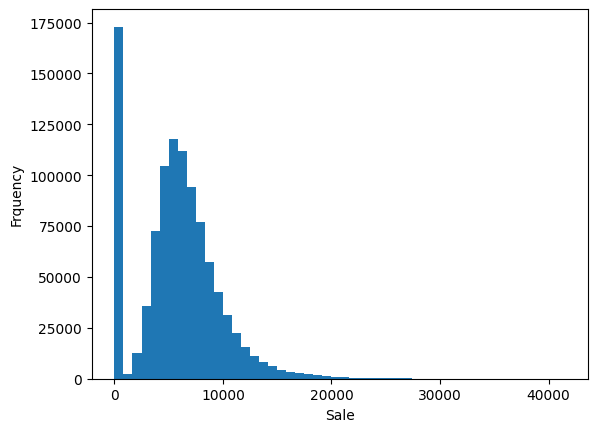

In [19]:
plt.hist(df['Sales'],bins=50)
plt.xlabel('Sale')
plt.ylabel('Frquency')
plt.show()

<Axes: ylabel='count'>

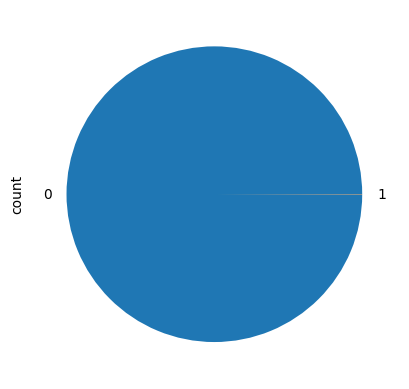

In [20]:
df[df['Sales']==0]['Open'].value_counts().plot(kind='pie')

The sales distribution shows a significant spike at zero sales. Further investigation revealed that 172,817 zero-sales records correspond to days when the stores were closed (Open = 0), while only 54 records had zero sales despite the store being open (Open = 1). This confirms that the large number of zero sales is primarily driven by store closures rather than poor sales performance. Therefore, the zero-sales observations are valid business events and should be considered carefully during data preprocessing and model development.

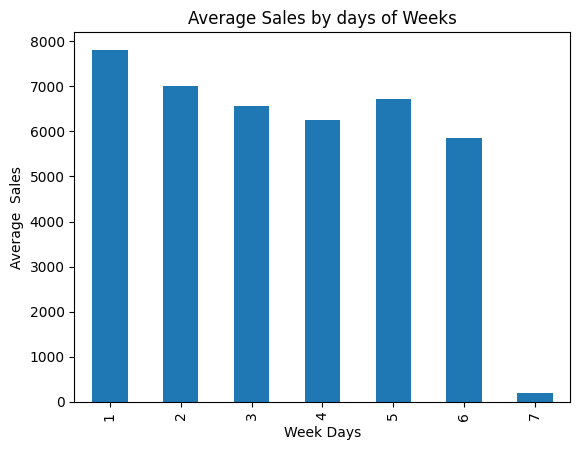

In [21]:
df.groupby('DayOfWeek')['Sales'].mean().plot(kind='bar')

plt.xlabel('Week Days')
plt.ylabel('Average  Sales')
plt.title('Average Sales by days of Weeks')
plt.show()

Average sales are highest at the beginning of the week, with Monday recording the strongest performance, followed by Tuesday. Sales generally decline during the middle of the week, although there is a slight increase on Friday before decreasing again on Saturday. Sunday records exceptionally low average sales, which is likely due to many stores being closed or operating for limited hours. Overall, customer purchasing activity appears to be strongest at the start of the week.

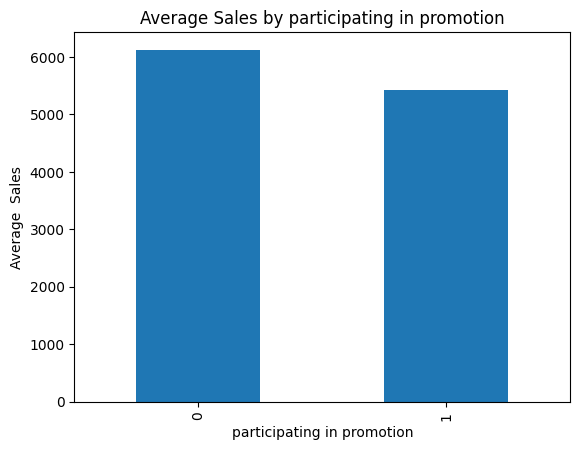

In [22]:
df.groupby('Promo2')['Sales'].mean().plot(kind='bar')

plt.xlabel('participating in promotion')
plt.ylabel('Average  Sales')
plt.title('Average Sales by participating in promotion')
plt.show()

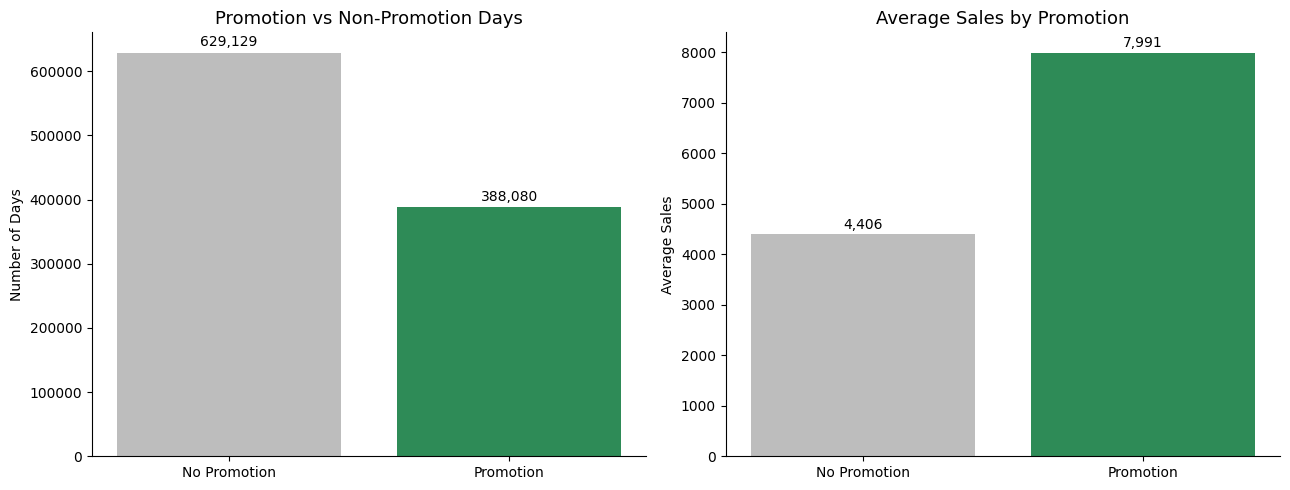

In [23]:
import matplotlib.pyplot as plt

labels = ['No Promotion', 'Promotion']
colors = ['#BDBDBD', '#2E8B57']   # Gray, Green

t1 = df.groupby('Promo')['Sales'].mean()
t2 = df['Promo'].value_counts().sort_index()

fig, ax = plt.subplots(1, 2, figsize=(13,5))

# Chart 1
bars1 = ax[0].bar(labels, t2.values, color=colors)

ax[0].set_title('Promotion vs Non-Promotion Days', fontsize=13)
ax[0].set_ylabel('Number of Days')

# Chart 2
bars2 = ax[1].bar(labels, t1.values, color=colors)

ax[1].set_title('Average Sales by Promotion', fontsize=13)
ax[1].set_ylabel('Average Sales')

# Value Labels
for bar in bars1:
    height = bar.get_height()
    ax[0].text(bar.get_x()+bar.get_width()/2,
               height+10000,
               f'{height:,.0f}',
               ha='center',
               fontsize=10)

for bar in bars2:
    height = bar.get_height()
    ax[1].text(bar.get_x()+bar.get_width()/2,
               height+100,
               f'{height:,.0f}',
               ha='center',
               fontsize=10)

ax[0].spines['top'].set_visible(False)
ax[0].spines['right'].set_visible(False)

ax[1].spines['top'].set_visible(False)
ax[1].spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

Promotional campaigns are active on 388,080 store-day records, compared to 629,129 records without promotions. Although promotions are conducted less frequently, they are associated with substantially higher sales performance. The average sales on promotion days are 7,991, compared to 4,406 on non-promotion days—an increase of approximately 81%. This suggests that short-term promotions have a strong positive association with sales and are likely an important driver of customer purchases.

In [24]:
pd.crosstab(df['DayOfWeek'],df['Promo'])

Promo,0,1
DayOfWeek,,
1,66970,77760
2,68084,77580
3,68085,77580
4,68265,77580
5,68265,77580
6,144730,0
7,144730,0


In [25]:
df[df['Promo']==1]['DayOfWeek'].unique()

array([5, 4, 3, 2, 1], dtype=int64)

Cross-analysis of Promo and DayOfWeek reveals that promotional activities occur exclusively on weekdays (Monday to Friday). No records indicate active promotions on Saturdays or Sundays. This suggests that promotional campaigns follow a weekday-only business strategy, possibly because customer traffic patterns differ on weekends or because weekends already experience sufficient demand without additional promotional support.

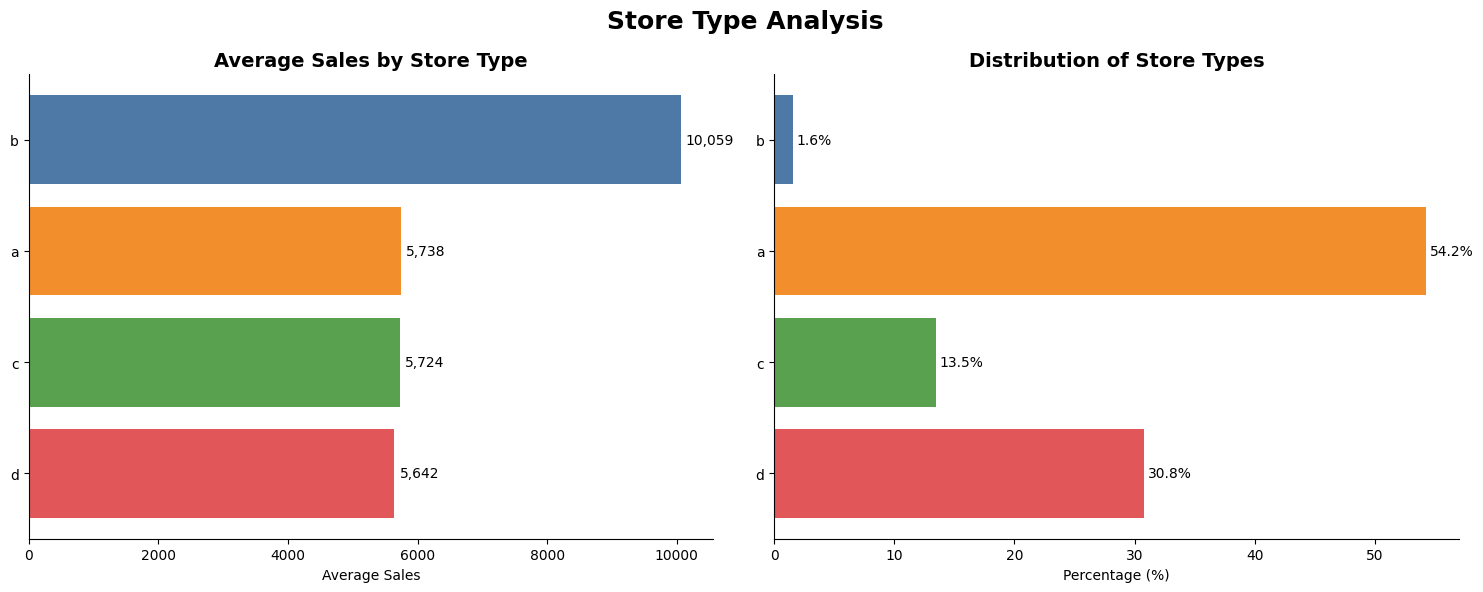

Insight:
- Store Type B has the highest average sales (~10,059).
- However, it represents only 1.5% of all stores.
- Most business revenue comes from Store Types A, C, and D due to their larger presence.


In [26]:
import matplotlib.pyplot as plt

# Data
avg_sales = df.groupby('StoreType')['Sales'].mean().sort_values(ascending=False)
store_percent = (df['StoreType'].value_counts(normalize=True)*100).reindex(avg_sales.index)

colors = ['#4E79A7', '#F28E2B', '#59A14F', '#E15759']

fig, ax = plt.subplots(1,2,figsize=(15,6))

# -------------------------------
# Left Chart : Average Sales
# -------------------------------
bars1 = ax[0].barh(avg_sales.index,
                   avg_sales.values,
                   color=colors)

ax[0].invert_yaxis()   # Highest value on top
ax[0].set_title("Average Sales by Store Type",
                fontsize=14,
                fontweight='bold')

ax[0].set_xlabel("Average Sales")

# Add values
for bar in bars1:
    width = bar.get_width()
    ax[0].text(width+80,
               bar.get_y()+bar.get_height()/2,
               f'{width:,.0f}',
               va='center')

# -------------------------------
# Right Chart : % of Stores
# -------------------------------
bars2 = ax[1].barh(store_percent.index,
                   store_percent.values,
                   color=colors)

ax[1].invert_yaxis()

ax[1].set_title("Distribution of Store Types",
                fontsize=14,
                fontweight='bold')

ax[1].set_xlabel("Percentage (%)")

# Add values
for bar in bars2:
    width = bar.get_width()
    ax[1].text(width+0.3,
               bar.get_y()+bar.get_height()/2,
               f'{width:.1f}%',
               va='center')

# Remove top/right borders
for a in ax:
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)

fig.suptitle("Store Type Analysis", fontsize=18, fontweight='bold')

plt.tight_layout()
plt.show()

print("Insight:")
print("- Store Type B has the highest average sales (~10,059).")
print("- However, it represents only 1.5% of all stores.")
print("- Most business revenue comes from Store Types A, C, and D due to their larger presence.")



#### The exploratory analysis provided valuable insights into the key drivers of sales, including promotions, store closures, store type, and temporal patterns. These findings will be leveraged during feature engineering to create informative variables that improve the forecasting model while ensuring the features remain interpretable from a business perspective

# Feature Engineering 



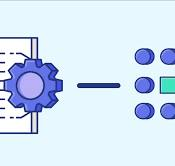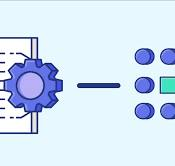

In [27]:
df['Date'] = pd.to_datetime(df['Date'])

In [28]:
df.duplicated(['Store','Date']).sum()

0

In [29]:
df=df.sort_values(['Store','Date'])

In [30]:
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Quarter'] = df['Date'].dt.quarter

In [31]:
df.groupby(['Year','Quarter'])['Sales'].mean()

Year  Quarter
2013  1         5,509.24
      2         5,416.10
      3         5,702.29
      4         6,000.62
2014  1         5,577.45
      2         5,709.21
      3         5,837.68
      4         6,273.71
2015  1         5,807.18
      2         5,858.44
      3         6,142.71
Name: Sales, dtype: float64

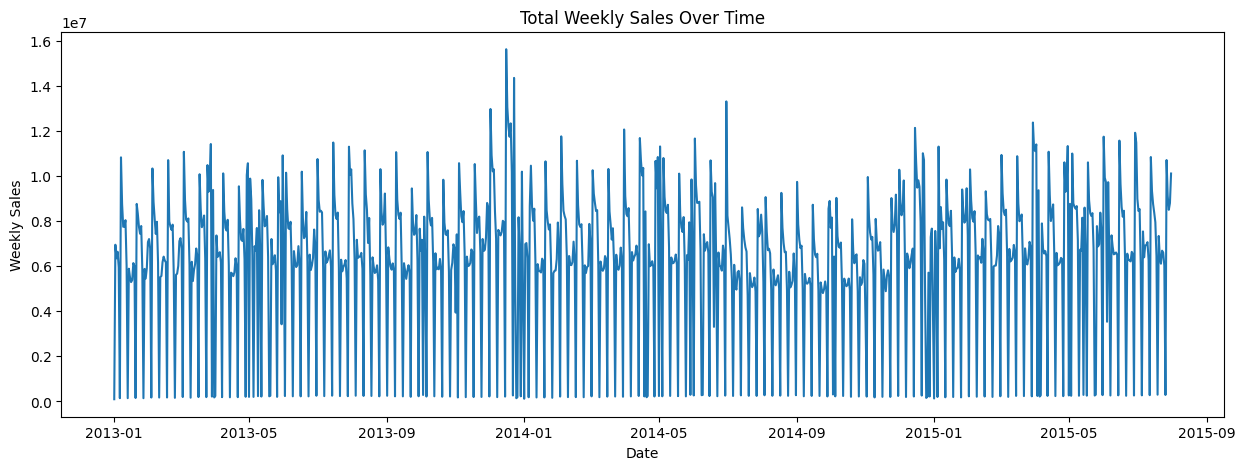

In [32]:
weekly_sales = (
    df.groupby(['Date'])['Sales']
      .sum()
      .sort_index()
)


plt.figure(figsize=(15,5))
plt.plot(weekly_sales)

plt.title('Total Weekly Sales Over Time')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')

plt.show()

In [33]:
store_a_sale = (df[df['Store']=='a'].groupby('Date')['Sales'].sum())

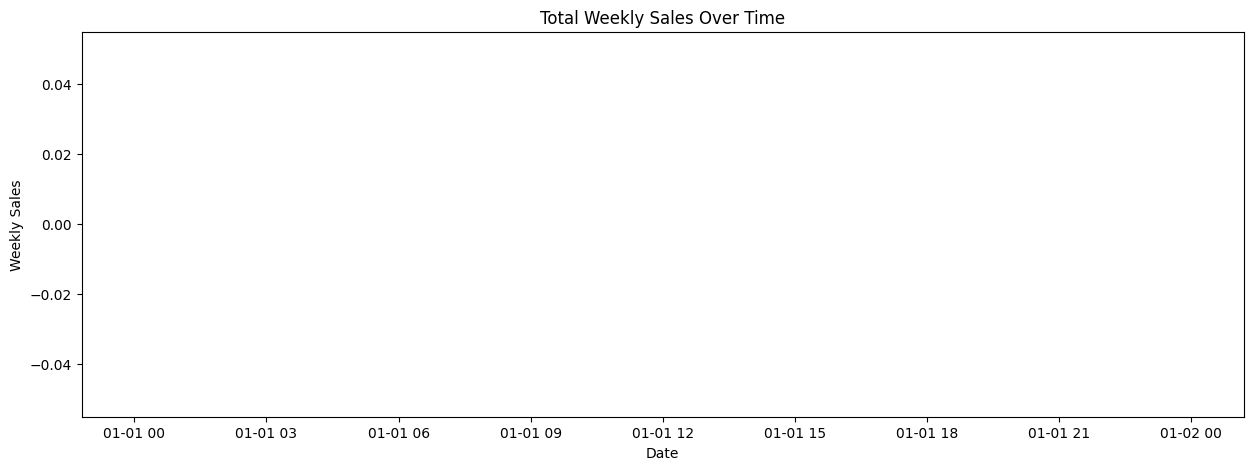

In [35]:
plt.figure(figsize=(15,5))
plt.plot(store_a_sale)

plt.title('Total Weekly Sales Over Time')
plt.xlabel('Date')
plt.ylabel('Weekly Sales')

plt.show()

In [36]:
weekly_sales

Date
2013-01-01       97235
2013-01-02     6949829
2013-01-03     6347820
2013-01-04     6638954
2013-01-05     5951593
                ...   
2015-07-27    10707292
2015-07-28     9115073
2015-07-29     8499962
2015-07-30     8798854
2015-07-31    10109742
Name: Sales, Length: 942, dtype: int64

In [37]:
lags=[1,7,14,28]
for lag in lags:
    df[f'lag_{lag}']=df.groupby('Store')['Sales'].shift(lag)

In [38]:
for lag in lags:
    print(lag,
          df[['Sales',f'lag_{lag}']].corr().iloc[0,1])

1 0.2783595122564684
7 0.6748943849608994
14 0.79367968414074
28 0.7761421542153769


In [39]:

roll = [7,14,28]
for r in roll:
    df[f'Rolling_{r}'] = df.groupby('Store')['Sales'].transform(
    lambda x: x.shift(1).rolling(r).mean())


In [40]:
for r in roll:
    print(r,
          df[['Sales',f'Rolling_{r}']].corr().iloc[0,1])

7 0.49781665770400196
14 0.5288745520962487
28 0.5352254990857478


In [69]:
df_model = df.dropna()

In [70]:
df_model.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,Year,Month,Quarter,lag_1,lag_7,lag_14,lag_28,Rolling_7,Rolling_14,Rolling_28
984875,1,2,2013-01-29,3725,522,1,0,0,0,c,...,2013,1,1,"4,055.00","5,720.00","3,900.00",0.00,"4,533.14","4,170.50","4,121.29"
983760,1,3,2013-01-30,4601,560,1,0,0,0,c,...,2013,1,1,"3,725.00","5,578.00","4,008.00","5,530.00","4,248.14","4,158.00","4,254.32"
982645,1,4,2013-01-31,4709,571,1,0,0,0,c,...,2013,1,1,"4,601.00","5,195.00","4,044.00","4,327.00","4,108.57","4,200.36","4,221.14"
981530,1,5,2013-02-01,5633,658,1,0,0,0,c,...,2013,2,1,"4,709.00","5,586.00","4,127.00","4,486.00","4,039.14","4,247.86","4,234.79"
980415,1,6,2013-02-02,5970,701,1,0,0,0,c,...,2013,2,1,"5,633.00","5,598.00","5,182.00","4,997.00","4,045.86","4,355.43","4,275.75"


In [71]:
df_model.shape

(985989, 23)

In [72]:
df_model.drop(columns='Date',inplace=True)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_20572\1271784376.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_model.drop(columns='Date',inplace=True)


In [73]:
str_col = df_model.select_dtypes(include='object').columns

In [74]:
df_model = pd.get_dummies(df_model, columns=str_col, dtype=int)


In [79]:
print(df_model.columns.duplicated().sum())

1


In [ ]:
df_mmodel.drop(columns=[''])

In [77]:
df.columns

Index(['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo',
       'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment',
       'CompetitionDistance', 'Promo2', 'Year', 'Month', 'Quarter', 'lag_1',
       'lag_7', 'lag_14', 'lag_28', 'Rolling_7', 'Rolling_14', 'Rolling_28'],
      dtype='object')

In [47]:
split_index = int(len(df_model) * 0.8)

train = df_model.iloc[:split_index]
test = df_model.iloc[split_index:]

In [48]:
X_train=train.drop(columns='Sales')
y_train=train['Sales']
X_test = test.drop(columns='Sales')
y_test=test['Sales']

In [53]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import pandas as pd
import numpy as np

# Define models
models = {
    "Linear Regression": LinearRegression(),
    
    "Random Forest": RandomForestRegressor(
        n_estimators=50,
        random_state=42
     )
    
    # ,"XGBoost": XGBRegressor(
    #     n_estimators=30,
    #     learning_rate=0.05,
    #     max_depth=6,
    #     random_state=42
    # )
}

results = []

# Train and Evaluate
for name, model in models.items():
    
    print(f"Training {name}...")
    
    model.fit(X_train, y_train)
    
    preds = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    
    results.append({
        "Model": name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R2": round(r2, 4)
    })

# Final comparison table
comparison = (
    pd.DataFrame(results)
      .sort_values("RMSE")
      .reset_index(drop=True)
)

comparison

Training Linear Regression...
Training Random Forest...


,Model,MAE,RMSE,R2
0,Random Forest,466.55,728.65,0.96
1,Linear Regression,747.80,"1,058.12",0.92


In [58]:
pred_rf = rf.predict(X_test)

print("MAE:", mean_absolute_error(y_test, pred_rf))
print("R2 :", r2_score(y_test, pred_rf))
print("MSE:",mean_squared_error(y_test, pred_rf))
print("MsqrtE:",math.sqrt(mean_squared_error(y_test, pred_rf)))

MAE: 471.092606077817
R2 : 0.961045061989699
MSE: 540991.6843740923
MsqrtE: 735.5213690805266


In [59]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.Series(
    rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importance.head(15))

Customers             0.78
lag_14                0.11
lag_1                 0.03
lag_28                0.02
Promo                 0.01
Rolling_28            0.01
CompetitionDistance   0.01
Rolling_7             0.01
DayOfWeek             0.01
Rolling_14            0.00
StoreType_d           0.00
Month                 0.00
lag_7                 0.00
Store                 0.00
Assortment_b          0.00
dtype: float64


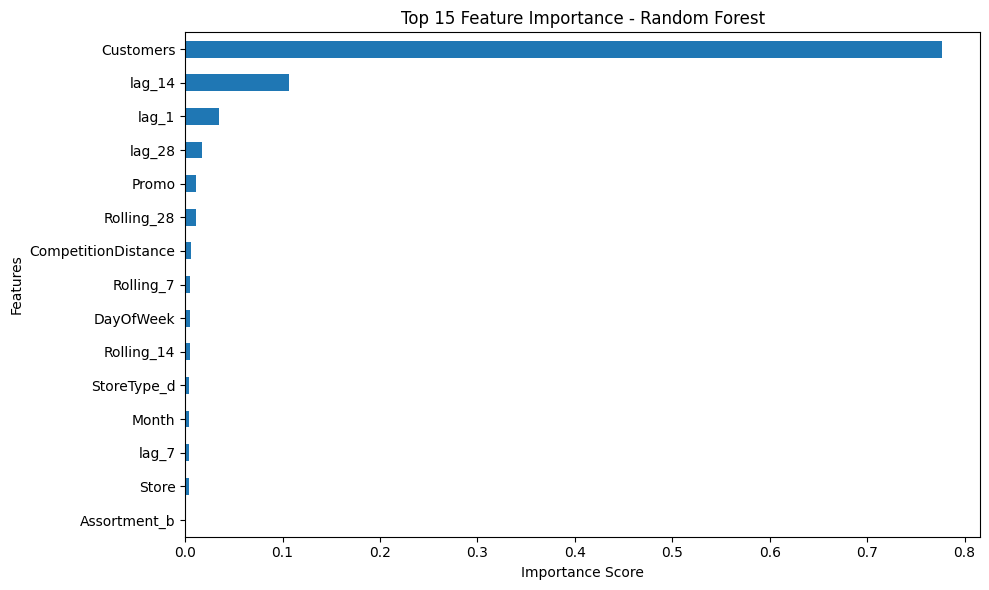

In [60]:
plt.figure(figsize=(10,6))

importance.head(15).sort_values().plot(kind='barh')

plt.title("Top 15 Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

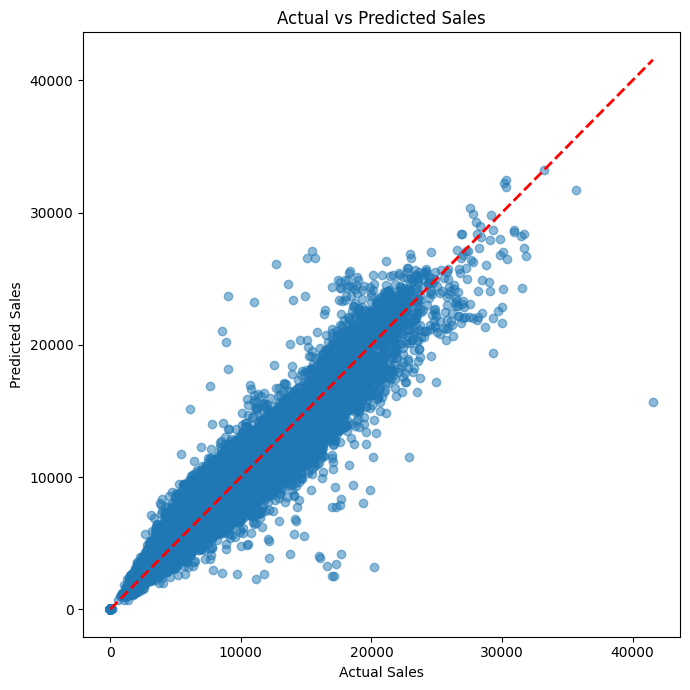

In [62]:
plt.figure(figsize=(7,7))

plt.scatter(y_test, pred_rf, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    linewidth=2
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")

plt.tight_layout()
plt.show()

The Actual vs Predicted scatter plot shows that the majority of observations lie close to the 45-degree reference line, indicating strong agreement between predicted and actual sales values. Prediction accuracy is particularly high for low- and medium-sales observations. A slightly larger spread is observed for high-sales values, suggesting that extreme sales events are more difficult to predict. A few outliers are present, but overall the model demonstrates excellent predictive performance, consistent with the achieved R² score of 0.961.

In [83]:

print("MAE:", mean_absolute_error(y_test_xg, preds))
print("R2 :", r2_score(y_test_xg, preds))
print("MSE:",mean_squared_error(y_test_xg, preds))
print("MsqrtE:",math.sqrt(mean_squared_error(y_test_xg, preds)))

MAE: 486.9765319824219
R2 : 0.9602298140525818
MSE: 552313.625
MsqrtE: 743.1780573994364
